# Realistic Model Demo

In [1]:
import numpy as np
from numpy.polynomial.legendre import leggauss
from scipy.interpolate import BSpline
from scipy.integrate import quad
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize
import pandas as pd
from matplotlib import pyplot as plt

## Model Specification

In [2]:
# suppressing factor
Lambda = 500
# range of Q2
Q2_min = 20
Q2_max = 200

def klin(z, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max):
    z = np.asarray(z, dtype=float)
    return 1/(Lambda**2) * ((z - Q2_min)**2) / ((Q2_max - Q2_min)**2)

def kquad(z, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max):
    z = np.asarray(z, dtype=float)
    return 1/(Lambda**4) * ((z - Q2_min)**2) / ((Q2_max - Q2_min)**2)

In [3]:
def alpha_s(Q2):
    return Q2

def sigma_T3_NLO(x, Q2, alpha_s, gV, CF=4/3):
    """
    This function returns only the NLO term, evaluated pointwise for x in (0,1).

    Parameters
    ----------
    x : float or array-like
        Bjorken x values. Should satisfy 0 < x < 1 (and not exactly 1).
    Q2 : float
        Q^2 (kept for signature consistency; alpha_s can be a function of Q2).
    alpha_s : float or callable
        Either a number αs(Q^2) or a function alpha_s(Q2)->float.
    gV : float
        g_V
    CF : float, default 4/3
        C_F

    Returns
    -------
    NLO : np.ndarray
        NLO (non-delta) contribution evaluated at x.
    """
    x = np.asarray(x, dtype=float)

    # get αs(Q^2)
    a = alpha_s(Q2) if callable(alpha_s) else float(alpha_s)

    # safe mask: avoid x<=0, x>=1, and x==1 singularity
    nlo = np.full_like(x, np.nan, dtype=float)
    mask = (x > 0.0) & (x < 1.0) & (x != 1.0)

    xm = x[mask]
    term = ((1.0 + xm**2) / (2.0 * (1.0 - xm))) * (np.log((1.0 - xm) / xm) - 3.0/4.0) - (1.0 + xm)

    nlo[mask] = (gV**2) * (CF * a / (2.0 * np.pi)) * term
    return nlo

In [4]:
# Build B-spline basis on [0,1]
def bspline_basis(degree, M, a, b):
    """
    Parameters
    ----------
    degree: degree of B-splines
    M: number of basis functions
    a, b: interval endpoints
    """

    # knots
    n_internal = M - degree - 1
    if n_internal > 0:
        inner_knots = np.linspace(a, b, n_internal + 2)[1:-1]
    else:
        inner_knots = np.array([])
    knots = np.r_[np.repeat(a, degree + 1), inner_knots, np.repeat(b, degree + 1)]
    #print("knots: ", knots)

    # basis functions
    I = np.eye(M)
    B = [BSpline(knots, I[m], degree, extrapolate=False) for m in range(M)]
    return B


# ----------------------------
# Helpers for (x,Q2) pairs
# ----------------------------
def _as_pairs(xQ2):
    """
    Normalize input into an (n,2) float array of (x, Q2).
    Accepts:
      - array-like shape (n,2)
      - tuple/list (x_array, Q2_array) with same length
    """
    if isinstance(xQ2, (tuple, list)) and len(xQ2) == 2 and np.ndim(xQ2[0]) > 0:
        x = np.asarray(xQ2[0], dtype=float)
        Q2 = np.asarray(xQ2[1], dtype=float)
        if x.shape != Q2.shape:
            raise ValueError(f"x and Q2 must have same shape, got {x.shape} vs {Q2.shape}")
        return np.column_stack([x.ravel(), Q2.ravel()]).astype(float)

    arr = np.asarray(xQ2, dtype=float)
    if arr.ndim != 2 or arr.shape[1] != 2:
        raise ValueError(f"xQ2 must have shape (n,2), got {arr.shape}")
    return arr


def _validate_x(x, idx=None):
    if x <= 0.0:
        where = f" at index {idx}" if idx is not None else ""
        raise ValueError(f"x must be in (0,1], got x={x}{where}.")


def build_A_matrix(
    xQ2,
    B,
    sigma_NLO,          # sigma_NLO(z, Q2) -> NLO part (no delta function)
    gV,        
    n_quad=1000,
):
    """
    Build A with entries
        A[r,k] = (gV**2)*x_r*B_k(x) + ∫_{x_r}^1 sigma_NLO(x_r/y, Q2_r) * B_k(y) dy

    
    Parameters
    ----------
    xQ2: (n,2) array of (x,Q2) pairs
    B: list of m basis functions, each B_k is a callable B_k(y)
    sigma_NLO: callable sigma_NLO(z, Q2) that can be vectorized in z
    gV: float, coupling constant
    n_quad: number of quadrature points for numerical integration        

    Returns
    -------
    A: (n, m) matrix of integrals
    """
    xQ2 = _as_pairs(xQ2)
    n_pts = xQ2.shape[0]
    m = len(B)

    nodes, weights = leggauss(n_quad)

    A = np.zeros((n_pts, m), dtype=float)

    for r, (x, Q2) in enumerate(xQ2):
        _validate_x(x, idx=r)

        # ----- LO part: dc * x * B_k(x) -----
        B_at_x = np.array([Bk(x) for Bk in B], dtype=float)
        A[r, :] += (gV**2) * x * B_at_x

        # ----- NLO part integral over y in [x, 1] -----
        if x >= 1.0:
            continue

        a, b = x, 1.0
        y = 0.5 * (b - a) * nodes + 0.5 * (b + a)
        jac = 0.5 * (b - a)

        z = x / y
        sig = sigma_NLO(z, Q2)  # shape (n_quad,)

        # evaluate all basis functions on y
        B_y = np.vstack([Bk(y) for Bk in B])  # shape (m, n_quad)

        # A[r,k] += ∫ sigma_NLO(z,Q2) * B_k(y) dy
        A[r, :] += jac * (B_y * (weights * sig)).sum(axis=1)

    return A


def v_c(c, xQ2, klin=klin, kquad=kquad):
    xQ2 = _as_pairs(xQ2)
    Q2 = xQ2[:, 1]
    return 1.0 + klin(Q2) * c + kquad(Q2) * (c**2)

def v_prime_c(c, xQ2, klin=klin, kquad=kquad):
    xQ2 = _as_pairs(xQ2)
    Q2 = xQ2[:, 1]
    return klin(Q2) + 2.0 * c * kquad(Q2)


def T_sm(
    xQ2,
    f,                  # f(y) -> array
    sigma_NLO,          # sigma_NLO(z, Q2) -> array (NLO part only)
    gV,
    n_quad=1000,
):
    """
    For each pair (x,Q2):
      T(x,Q2) = (gV**2) * x * f(x) + ∫_x^1 f(y) * sigma_NLO(x/y, Q2) dy


    Parameters
    ----------
    xQ2      : (n,2) array of (x,Q2) pairs
    f        : callable f(y) -> array same shape as y
    sigma_NLO : callable sigma_NLO(z, Q2) -> array same shape as z
    gV      : float, coupling constant
    n_quad  : int, number of Gauss-Legendre points for numerical integration

    Returns
    -------
    T_vec    : (n,) array of T_SM values
    """
    xQ2 = _as_pairs(xQ2)
    n_pts = xQ2.shape[0]

    nodes, weights = np.polynomial.legendre.leggauss(n_quad)
    T_vec = np.zeros(n_pts, dtype=float)

    for r, (x, Q2) in enumerate(xQ2):
        _validate_x(x, idx=r)

        # ----- LO contribution: dc * x * f(x) -----
        T_LO = (gV**2) * x * float(np.asarray(f(x)))

        if x >= 1.0:
            T_vec[r] = T_LO
            continue

        # ----- NLO contribution -----
        a, b = x, 1.0
        y = 0.5 * (b - a) * nodes + 0.5 * (b + a)
        jac = 0.5 * (b - a)

        z = x / y
        integrand = f(y) * sigma_NLO(x=z, Q2=Q2)

        T_NLO = jac * np.sum(weights * integrand)

        T_vec[r] = T_LO + T_NLO

    return T_vec


def T_sm_basis(A, beta):
    return A @ beta

def gaussian_mean_basis(c, beta, A, xQ2, klin=klin, kquad=kquad):
    v = v_c(c, xQ2, klin=klin, kquad=kquad)        
    T = T_sm_basis(A, beta)
    return v * T

def gaussian_mean(c, T, xQ2, klin=klin, kquad=kquad):
    v = v_c(c, xQ2, klin=klin, kquad=kquad)
    return v * T

def build_K_matrix(c, A, xQ2, klin=klin, kquad=kquad):
    v = v_c(c, xQ2, klin=klin, kquad=kquad)
    return np.diag(v) @ A

def build_K_prime_matrix(c, A, xQ2, klin=klin, kquad=kquad):
    v_prime = v_prime_c(c, xQ2, klin=klin, kquad=kquad)
    return np.diag(v_prime) @ A

### Likelihood and Estimation Functions

In [5]:
# Negative log-likelihood and gradient
def make_nll_and_grad(D, A, v, v_prime, xQ2, Sigma=None):
    """
    D     : (N,) data vector
    A     : (N, M) matrix from T(f) (T(f) = A @ beta)
    v     : callable     v(c) returns (N,) vector
    v_prime: callable    v_prime(c) returns (N,) vector (derivative of v)
    xQ2: (n, 2) array of (x,Q2) pairs
    Sigma : (N, N) known covariance (default None; identity matrix)
    """
    N, M = A.shape

    if Sigma is not None:
        # Cholesky factorization of Sigma
        cF, lower = cho_factor(Sigma, check_finite=False)
        def Sigma_inv(v):    # Sigma^{-1} v
            return cho_solve((cF, lower), v, check_finite=False)
    else:
        def Sigma_inv(v):
            return v


    def nll(theta):
        beta = theta[:M]
        c = theta[-1]
        vc = v(c, xQ2=xQ2)
        mu = vc * (A @ beta)
        r = D - mu
        loss = 0.5 * r @ Sigma_inv(r)

        return loss

    def grad(theta):
        beta = theta[:M]
        c = theta[-1]

        vc = v(c, xQ2=xQ2)
        dv = v_prime(c, xQ2=xQ2)
        mu = vc * (A @ beta)         
        r = D - mu
        Sigma_inv_r = Sigma_inv(r)

        # d(NLL)/d beta = - (diag(v(c)) A)^T Sigma^{-1} r
        g_beta = - ((vc[:, None] * A).T @ Sigma_inv_r)

        # d(NLL)/d c = - (dv(c) \odot (A beta))^T Sigma^{-1} r
        g_c = - (dv * (A @ beta)).T @ Sigma_inv_r

        return np.r_[g_beta, g_c]

    return nll, grad


def fit_beta_c(D, A, v, v_prime, w_norm, xQ2, Sigma=None, beta0=None, c0=0.0,
               loss_curve=False, nonneg_beta=False):
    """
    Fit parameters beta and c by joint minimization of the negative log-likelihood.
    
    D     : (N,) data vector
    A     : (N, M) matrix from T(f) (T(f) = A @ beta)
    v     : callable     v(c) returns (N,) vector
    v_prime: callable    v_prime(c) returns (N,) vector (derivative of v)
    w_norm: (M,) normalization weights, int B_m(y) dy
    xQ2: (N, 2) array of (x,Q2) pairs
    Sigma : (N, N) known covariance (default None; identity matrix)
    beta0 : (M,) initial guess for beta (optional)
    c0    : initial guess for c (default 0.0)
    nonneg_beta : if True, enforce beta >= 0 (default False)
    """
   
    N, M = A.shape
    if beta0 is None:
        # randomly initialize beta0
        b = np.random.rand(M)
        # normalize w^T b = 1
        beta0 = b / (w_norm @ b)
    #print("initial beta:", beta0)
    #print("w_norm:", w_norm)
    #print("beta sum w_norm:", beta0 @ w_norm)

    theta0 = np.r_[beta0, c0]

    nll, grad = make_nll_and_grad(D, A, v, v_prime, xQ2=xQ2, Sigma=Sigma)

    # Equality constraint: w_norm^T beta = 1
    cons = [{
        "type": "eq",
        "fun":  lambda x: float(w_norm @ x[:M] - 1.0),
        "jac":  lambda x: np.r_[w_norm, 0.0]
    }]


    if loss_curve:
        loss_history = []

        def callback(theta):
            loss_history.append(nll(theta))
    

    # Bounds:
    if nonneg_beta:
        bounds = [(0.0, None)] * M + [(None, None)]
    else:
        bounds = [(None, None)] * (M + 1)

    res = minimize(nll, theta0, jac=grad, method="SLSQP",
                   constraints=cons, bounds=bounds,
                   options=dict(maxiter=1000, ftol=1e-10),
                   callback=callback if loss_curve else None)
    res.beta_hat = res.x[:M]
    res.c_hat = res.x[-1]

    if loss_curve:
        return res, loss_history
    return res


def mle_beta(D, A, c, v, xQ2, w_norm, Sigma=None, beta0=None, nonneg_beta=True, beta_opt="SLSQP"):
    """
    Find MLE of beta given c

    Args
    ----
    D : (N,)         data vector
    A : (N, M)       design matrix
    c : float        given value of c
    v : callable     v(c) returns (N,) vector
    xQ2: (N, 2) array of (x,Q2) pairs
    w_norm: (M,)     normalization weights, int B_m(y) dy
    Sigma : (N, N)   covariance (PD). If None, assume identity matrix
    beta0 : (M,)     initial guess for beta (optional)
    nonneg_beta :    if True, enforce beta >= 0 (default False)
    beta_opt: str    optimization method for beta ("SLSQP" or "closed_form")

    Returns
    -------
    beta_hat : (M,)  MLE of beta given c
    """

    N, M = A.shape

    # Sigma^{-1} v
    if Sigma is not None:
        cF, lower = cho_factor(Sigma, check_finite=False)
        Sigma_inv = lambda v: cho_solve((cF, lower), v, check_finite=False)
    else:
        Sigma_inv = lambda v: v

    vc = v(c, xQ2=xQ2)

    if beta0 is None:
        # randomly initialize beta0
        b = np.random.rand(M)
        # normalize w^T b = 1
        beta0 = b / (w_norm @ b)

    if beta_opt == "SLSQP":
        # solve beta via constrained optimization
        def loss(beta):
            mu = vc * (A @ beta)
            r  = D - mu
            return 0.5 * r @ Sigma_inv(r)

        def grad(beta):
            mu = vc * (A @ beta)
            r  = D - mu
            # gradient of 0.5 * r^T S^{-1} r w.r.t beta
            return (vc[:, None] * A).T @ Sigma_inv(r)

        cons = {'type': 'eq',
                'fun': lambda beta: float(w_norm @ beta - 1.0),
                'jac': lambda beta: w_norm}
        
        # Bounds:
        if nonneg_beta:
            bounds = [(0.0, None)] * M
        else:
            bounds = [(None, None)] * M

        res = minimize(loss, beta0, jac=grad, method='SLSQP', constraints=cons, bounds=bounds)
        iter = 0
        while not res.success and iter < 5:
            # try it again with different init
            b = np.random.rand(M)
            # normalize w^T b = 1
            beta0 = b / (w_norm @ b)
            res = minimize(loss, beta0, jac=grad, method='SLSQP', constraints=cons, bounds=bounds)
            iter += 1
        if not res.success:
            raise RuntimeError(f"Optimization for beta failed: {res.message}")
        return res.x
    elif beta_opt == "closed_form":
        # Build W = diag(v(c)) A without forming diag explicitly
        nu = np.asarray(v(c, xQ2=xQ2)).reshape(-1)
        if nu.shape[0] != N:
            raise ValueError(f"v(c) must return shape {(N,)}, got {nu.shape}.")
        W = nu[:, None] * A  # (N, M)

        # U = W^T Sigma^{-1} W,  b = W^T Sigma^{-1} D
        SinvW = np.column_stack([Sigma_inv(W[:, j]) for j in range(M)])  # (N, M)
        U = W.T @ SinvW                                                  # (M, M)
        b = W.T @ Sigma_inv(D)                                           # (M,)

        # Solve KKT system:
        # [U  w] [beta]   [b]
        # [w^T 0] [lam ] = [1]
        KKT = np.zeros((M + 1, M + 1), dtype=float)
        KKT[:M, :M] = U
        KKT[:M, M] = w_norm
        KKT[M, :M] = w_norm
        rhs = np.zeros(M + 1, dtype=float)
        rhs[:M] = b
        rhs[M] = 1.0
    
        sol = np.linalg.solve(KKT, rhs)

        beta_hat = sol[:M]
        if nonneg_beta and np.any(beta_hat < 0):
            raise ValueError("Closed-form beta has negative entries; try using 'SLSQP' option.")
        return beta_hat
    else:
        raise ValueError("Invalid beta_opt method.")

def mle_c(D, A, v, beta, xQ2, Sigma=None, c_opt="scipy_optimize"):
    """
    Find MLE of c given beta

    Args
    ----
    D : (N,)         data vector
    A : (N, M)       design matrix
    v : callable     v(c) returns (N,) vector
    beta : (M,)      given value of beta
    xQ2: (N, 2) array of (x,Q2) pairs
    Sigma : (N, N)   covariance (PD). Use if full matrix.
    c_opt : str      optimization method for c ("scipy_optimize" or "grid_search")
    w_norm: (M,)     normalization weights, int B_m(y) dy

    Returns
    -------
    c_hat : float    MLE of c given v
    """

    N, M = A.shape

    # Fast operator v -> Sigma^{-1} v
    if Sigma is not None:
        cF, lower = cho_factor(Sigma, check_finite=False)
        Sigma_inv = lambda v: cho_solve((cF, lower), v, check_finite=False)
    else:
        Sigma_inv = lambda v: v

    def nll(c):
        vc = v(c, xQ2=xQ2)
        mu = vc * (A @ beta)
        r = D - mu
        loss = 0.5 * r @ Sigma_inv(r)
        return loss


    if c_opt == "scipy_optimize":
        res = minimize(lambda c: nll(c), x0=0.0, method='L-BFGS-B')
        if not res.success:
            res = minimize(lambda c: nll(c), x0=0.0, method='Nelder-Mead')
            if not res.success:
                raise RuntimeError(f"Optimization failed: {res.message}")
        return res.x[0]
    elif c_opt == "grid_search":
        # Simple grid search over a reasonable range of c values
        c_grid = np.linspace(-5.0, 5.0, 1000)
        nll_values = np.array([nll(c) for c in c_grid])
        idx_min = np.argmin(nll_values)
        return c_grid[idx_min]
    else:
        raise ValueError("Invalid c_opt method.")
    

def mle_beta_c_ca(D, A, v, xQ2, Sigma=None, w_norm=None, c0=0, beta0=None, beta_opt="closed_form", c_opt="scipy_optimize", nonneg_beta=False, eps=1e-6, max_iter=10):
    """
    MLE of (beta, c) by coordinate ascent

    Args
    ----
    D : (N,)         data vector
    A : (N, M)       design matrix
    v : callable     v(c) returns (N,) vector
    xQ2: (N, 2) array of (x,Q2) pairs
    Sigma : (N, N)   covariance (PD). Use if full matrix.
    w_norm: (M,)     normalization weights, int B_m(y) dy
    c0 : float       initial guess for c (optional)
    beta0 : (M,)     initial guess for beta (optional)
    c_opt : str      optimization method for c ("scipy_optimize" or "grid_search")

    Returns
    -------
    beta_hat : (M,)  MLE of beta
    c_hat : float    MLE of c
    """
    # initialize
    c_hat = c0
    if beta0 is None:
        # randomly initialize beta0
        b = np.random.rand(A.shape[1])
        # normalize w^T b = 1
        beta0 = b / (w_norm @ b)
    beta_hat = beta0

    print(f"Initialization: c={c_hat}, ||beta||_2={np.linalg.norm(beta_hat, ord=2)}")
    # iterate until convergence or reach max_iter
    for iter in range(max_iter):
        beta_new = mle_beta(D, A, c_hat, v, xQ2, w_norm, Sigma, beta0, nonneg_beta, beta_opt)
        c_new = mle_c(D, A, v, beta_new, xQ2, Sigma, c_opt)

        if abs(c_new - c_hat) < eps and np.linalg.norm(beta_new - beta_hat, ord=2) < eps:
            break
        #if iter % 5 == 0:
        print(f"Iter {iter+1}: c={np.round(c_new, 4)}, ||beta||_2={np.round(np.linalg.norm(beta_new, ord=2), 4)},"
                f" c_change={np.round(abs(c_new - c_hat), 4)}, beta_change={np.round(np.linalg.norm(beta_new - beta_hat, ord=2), 4)}")
        c_hat = c_new
        beta_hat = beta_new
    print(f"Final: c={np.round(c_hat, 4)}, ||beta||_2={np.round(np.linalg.norm(beta_hat, ord=2), 4)} after {iter+1} iters")
        
    if iter == max_iter - 1:
        print("Warning: Coordinate ascent did not converge within max_iter")

    return beta_hat, c_hat



def one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, Sigma=None, s2_diag=None):
    """
    One-step estimator for c using the EIF with beta nuisance under constraint w_norm^T beta = 1.

    Model:
        mu(c,beta) = K(c) @ beta
        dmu/dc     = K_prime(c) @ beta
    Nuisance tangent restriction:
        beta_e = beta + e h with w_norm^T h = 0.

    Parameters
    ----------
    D       : (N,) data vector
    K       : (N, M) matrix, mu = K @ beta
    K_prime : (N, M) derivative wrt c, dmu/dc = K_prime @ beta
    beta_hat: (M,) estimated beta (ideally satisfies w_norm^T beta_hat ≈ 1)
    c_hat   : float, current estimate of c
    w_norm  : (M,) normalization weights, enforces w_norm^T beta = 1
    Sigma   : (N, N) covariance (optional). If None and s2_diag None => identity.
    s2_diag : (N,) diagonal of Sigma if diagonal (preferred). If provided, Sigma ignored.

    Returns
    -------
    c_one_step : float
    eif        : float
    info       : dict (useful diagnostics)
    """

    D = np.asarray(D).reshape(-1)
    beta_hat = np.asarray(beta_hat).reshape(-1)
    w_norm = np.asarray(w_norm).reshape(-1)
    K = np.asarray(K)
    K_prime = np.asarray(K_prime)

    N, M = K.shape

    if D.shape[0] != N:
        raise ValueError(f"D has length {D.shape[0]} but K has {N} rows.")
    if K_prime.shape != (N, M):
        raise ValueError(f"K_prime must have shape {(N, M)}, got {K_prime.shape}.")
    if beta_hat.shape[0] != M:
        raise ValueError(f"beta_hat has length {beta_hat.shape[0]} but K has {M} cols.")
    if w_norm.shape[0] != M:
        raise ValueError(f"w_norm has length {w_norm.shape[0]} but K has {M} cols.")

    # --- Define Sigma^{-1} operator ---
    if s2_diag is not None:
        s2_diag = np.asarray(s2_diag).reshape(-1)
        if s2_diag.shape[0] != N:
            raise ValueError(f"s2_diag has length {s2_diag.shape[0]} but N={N}.")
        if np.any(s2_diag <= 0):
            raise ValueError("All entries of s2_diag must be positive.")

        # Apply Sigma^{-1} to vector/matrix
        def Sigma_inv(v):
            v = np.asarray(v)
            return v / s2_diag[:, None] if v.ndim == 2 else v / s2_diag
    else:
        if Sigma is None:
            def Sigma_inv(v):
                return np.asarray(v)
        else:
            Sigma = np.asarray(Sigma)
            if Sigma.shape != (N, N):
                raise ValueError(f"Sigma must have shape {(N, N)}, got {Sigma.shape}.")
            cF, lower = cho_factor(Sigma, check_finite=False)
            def Sigma_inv(v):
                return cho_solve((cF, lower), v, check_finite=False)

    # --- Plug-in estimates ---
    mu_hat = K @ beta_hat                  # (N,)
    r_hat = D - mu_hat                     # (N,)
    mu_prime_hat = K_prime @ beta_hat      # (N,)

    # --- Build G = K^T Sigma^{-1} K and b = K^T Sigma^{-1} mu_prime_hat ---
    SinvK = Sigma_inv(K)                   # (N, M)
    #SinvK = K
    U = 2 * K.T @ SinvK                    # (M, M)
    b = 2 * K.T @ Sigma_inv(mu_prime_hat)  # (M,)
    #b = 2 * K.T @ mu_prime_hat             # (M,)

    # --- Constrained optimization: minimize ||mu' - K h||_{Sigma^{-1}}^2 s.t. w^T h = 0 ---
    # KKT:
    # [ U   w ] [h]   [b]
    # [ w^T 0 ] [λ] = [0]
    KKT = np.block([
        [U,          w_norm[:, None]],
        [w_norm[None, :], np.zeros((1, 1))]
    ])
    rhs = np.concatenate([b, np.array([0.0])])

    # Solve KKT conditions.
    sol = np.linalg.solve(KKT, rhs)

    # projected nuisance coefficients (satisfies w^T h = 0)
    h_star = sol[:M]
    lam = float(sol[M])

    # delta_hat = (I - Pi) mu_prime_hat
    delta_hat = mu_prime_hat - K @ h_star

    # --- EIF and one-step update ---
    num = float(delta_hat.T @ Sigma_inv(r_hat))
    den = float(delta_hat.T @ Sigma_inv(delta_hat))
    #num = float(delta_hat.T @ r_hat)
    #den = float(delta_hat.T @ delta_hat)

    if not np.isfinite(den) or den <= 0:
        print(f"Invalid EIF denominator (information): den={den}. "
                           "This suggests non-identifiability or numerical issues.")

    eif = num / den
    c_one_step = float(c_hat + eif)

    info = {
        "c_hat": c_hat,
        "num": num,
        "den": den,
        "eif": eif,
        "lambda": lam,
        "w_dot_beta": float(w_norm @ beta_hat),
        "w_dot_h": float(w_norm @ h_star),
    }

    return c_one_step, info


### Plotting functions

In [6]:
def plot_by_Q2(
    Y,
    xQ2,                         # shape (n_pts, 2): columns are (x, Q2)
    ncols=2,
    y_label="Value",
    series_styles=None,
    default_style=None,
    show_legend=True,
    sort_x_within_panel=True,
    q2_round_decimals=12,        # helps group nearly-equal floating Q2s
):
    """
    Plot one or multiple vectorized series by Q^2 panels using explicit (x,Q2) pairs.

    Parameters
    ----------
    Y : array-like, list/tuple of array-like, or dict[str, array-like]
        Each series must be length n_pts, aligned with xQ2 rows.
    xQ2 : array-like, shape (n_pts, 2)
        Rows are (x, Q2) pairs in the same order as Y vectors.
    ncols : int
        Number of subplot columns.
    y_label : str
        Y-axis label for each panel.
    series_styles : dict, optional
        Per-series style dict. Each may include 'kind' in {"line","scatter"} plus matplotlib kwargs.
    default_style : dict, optional
        Default style dict; may include 'kind'.
    show_legend : bool
        Show legend (only in the first panel by default).
    sort_x_within_panel : bool
        Sort points by x within each Q2 panel before plotting.
    q2_round_decimals : int
        Q2 grouping key uses round(Q2, q2_round_decimals) to avoid float-equality issues.

    Notes
    -----
    - If a given Q2 has repeated x values, line plots will connect them in sorted order.
      If that's undesirable, use kind="scatter" for that series.
    """
    xQ2 = np.asarray(xQ2, dtype=float)
    if xQ2.ndim != 2 or xQ2.shape[1] != 2:
        raise ValueError(f"xQ2 must have shape (n_pts, 2), got {xQ2.shape}")

    x = xQ2[:, 0]
    Q2 = xQ2[:, 1]
    n_pts = xQ2.shape[0]

    # Normalize Y into list of (label, vec)
    series = []
    if isinstance(Y, dict):
        for lab, vec in Y.items():
            series.append((lab, np.asarray(vec, dtype=float)))
    elif isinstance(Y, (list, tuple)):
        for i, vec in enumerate(Y):
            series.append((f"Y{i+1}", np.asarray(vec, dtype=float)))
    else:
        series = [("Y", np.asarray(Y, dtype=float))]

    # Validate lengths
    for lab, vec in series:
        if vec.size != n_pts:
            raise ValueError(f"Series '{lab}' has length {vec.size}, expected {n_pts}.")

    if series_styles is None:
        series_styles = {}
    if default_style is None:
        default_style = dict(kind="line", linewidth=2)

    # Group by (rounded) Q2
    Q2_key = np.round(Q2, q2_round_decimals)
    uniq_keys = np.unique(Q2_key)

    # Keep a stable ordering by increasing actual Q2 (using mean within group)
    q2_values = []
    idx_groups = []
    for k in uniq_keys:
        idx = np.where(Q2_key == k)[0]
        idx_groups.append(idx)
        q2_values.append(np.mean(Q2[idx]))
    order = np.argsort(q2_values)
    idx_groups = [idx_groups[i] for i in order]
    q2_values = [q2_values[i] for i in order]

    n_Q2 = len(idx_groups)
    nrows = int(np.ceil(float(n_Q2) / float(ncols)))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(6 * ncols, 3 * nrows),
        sharex=True
    )
    axes = np.atleast_1d(axes).ravel()

    for i, (idx, q2_val) in enumerate(zip(idx_groups, q2_values)):
        ax = axes[i]

        # optionally sort by x within the panel
        if sort_x_within_panel:
            ordx = np.argsort(x[idx])
            idxp = idx[ordx]
        else:
            idxp = idx

        x_i = x[idxp]

        for lab, vec in series:
            y_i = vec[idxp]

            style = default_style.copy()
            style.update(series_styles.get(lab, {}))
            kind = style.pop("kind", "line")

            if kind == "scatter":
                ax.scatter(x_i, y_i, label=lab, **style)
            else:
                ax.plot(x_i, y_i, label=lab, **style)

        ax.set_title(r"$Q^2 = {:.6g}$".format(q2_val))
        ax.set_ylabel(y_label)
        ax.grid(True)

        if show_legend and i == 0:
            ax.legend()

    # Turn off unused axes
    for ax in axes[n_Q2:]:
        ax.axis("off")

    # X-label on bottom row (any axes that are actually used)
    start = max(0, n_Q2 - ncols)
    for ax in axes[start:n_Q2]:
        ax.set_xlabel(r"$x$")

    plt.tight_layout()
    plt.show()


## Define PDF

### Basis functions

Right now the true PDF is given by basis expansion with some unknown coefficients beta_true. We can modify this to include a more realistic PDF.

In [7]:
degree_true = 3
M_true = 20
rng = np.random.default_rng(seed=12345)
beta_true = rng.normal(size=M_true)
#x_coef = np.linspace(0, 1, M)
#beta = np.sin(2*np.pi*x_coef)
beta_true = np.abs(beta_true)
# make the first and last one to be zero so that the density is zero at the boundaries
#beta[0] = 0.0
#beta[-1] = 0.0

B_true = bspline_basis(degree_true, M_true, 0, 1)

# normalization integrals for each basis
w_norm_true = np.array([Bk.integrate(0, 1) for Bk in B_true])
beta_true = beta_true * (1.0 / (beta_true @ w_norm_true))
print("linear constraint:", beta_true @ w_norm_true)

# Compute the expansion f(y) = sum_k beta_k * B_k(y)
def f(u, beta=beta_true, B=B_true):
    fy = 0.0
    for betak, Bk in zip(beta, B):
        fy += betak * Bk(u)
    return fy

# make sure f is a density function
print("Integral of f(y) over [0,1]:", quad(lambda y: f(y), 0, 1)[0])

linear constraint: 1.0
Integral of f(y) over [0,1]: 1.0000000002677323


### Plot

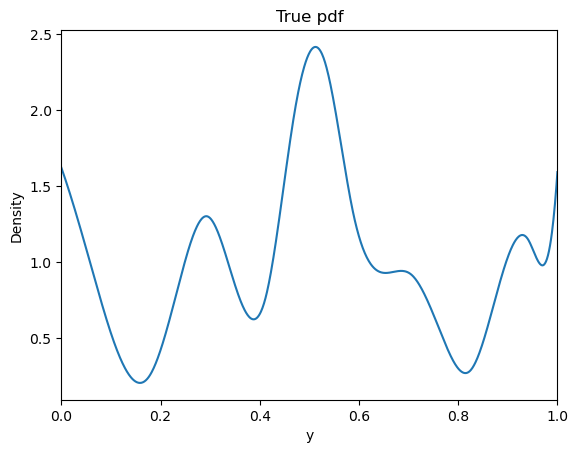

In [8]:
# plot
pt = np.linspace(0, 1, 1000)
plt.plot(pt, f(pt))
plt.xlim(0, 1)
plt.xlabel("y")
plt.ylabel("Density")
plt.title("True pdf")
plt.show()

## Generate Data

In [22]:
# True c parameter
c = 5e5

Q2_grid = [30, 50, 80, 100, 120, 150]
x_grid = np.linspace(0.01, 0.99, 50)

xQ2 = np.array([(x, Q2) for Q2 in Q2_grid for x in x_grid], dtype=float)

In [23]:
T = T_sm(xQ2=xQ2, f=f, 
    sigma_NLO=lambda x, Q2: sigma_T3_NLO(x, Q2, alpha_s=alpha_s, gV=0.5),
    gV=0.5,
    n_quad=1000
)

mu = gaussian_mean(c=c, T=T, xQ2=xQ2, klin=klin, kquad=kquad)

In [24]:
# Generate Gaussian data with mean = gaussian_mean and diagonal covariance
variance = 10000
D = mu + np.sqrt(variance) * np.random.randn(len(mu))
Sigma = np.eye(len(mu)) * variance

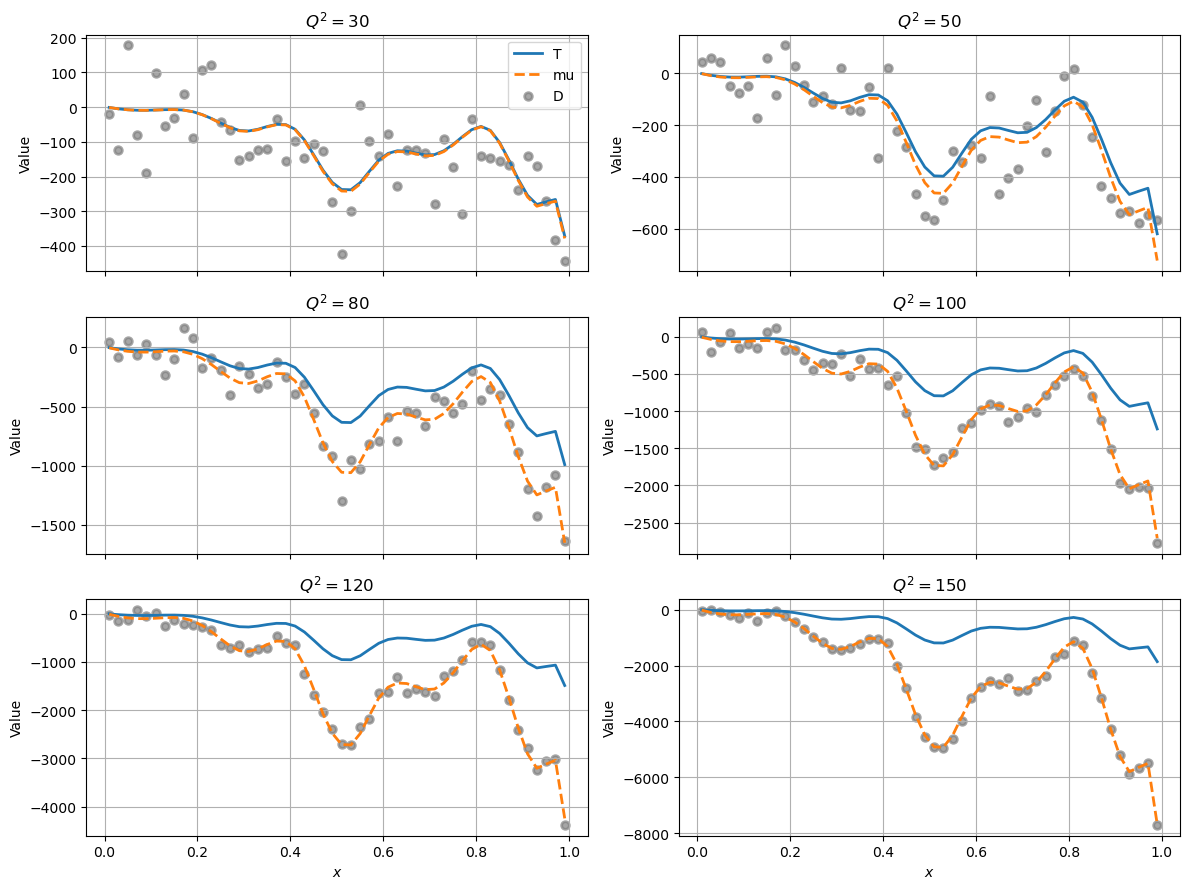

In [25]:
plot_by_Q2({"T": T, "mu": mu, "D": D}, xQ2=xQ2, series_styles={
    "T": dict(linestyle="-", linewidth=2, color="C0"),
    "mu": dict(linestyle="--", linewidth=2, color="C1"),
    "D": dict(kind="scatter", color="gray", s=30, alpha=0.7)
})

## Estimation

In [26]:
# Specify spline basis for fitting

# Degree of B-splines
degree = 3
# Number of basis
M = 20

B = bspline_basis(degree, M, 0.0, 1.0)

w_norm = np.array([Bk.integrate(0.0, 1.0) for Bk in B])

A = build_A_matrix(xQ2=xQ2, B=B, sigma_NLO=lambda x, Q2: sigma_T3_NLO(x, Q2, alpha_s=alpha_s, gV=0.5), 
                              gV=0.5, n_quad=2000)

In [27]:
beta_hat = mle_beta(D=D, A=A, c=5e5, v=v_c, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, beta0=None, nonneg_beta=True, beta_opt="SLSQP")
c_hat = mle_c(D=D, A=A, v=v_c, beta=beta_hat, xQ2=xQ2, Sigma=Sigma, c_opt="scipy_optimize")

In [ ]:
beta_hat, c_hat = mle_beta_c_ca(D=D, A=A, v=v_c, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, c0=0.0, beta0=None, 
                beta_opt="SLSQP", c_opt="scipy_optimize", nonneg_beta=True, max_iter=20, eps=10)

Initialization: c=0.0, ||beta||_2=5.171989894954593
Iter 1: c=437187.7626, ||beta||_2=5.172, c_change=437187.7626, beta_change=0.0003
Final: c=437187.7626, ||beta||_2=5.172 after 2 iters


In [19]:
# fit beta and c
res, loss_history = fit_beta_c(D=D, A=A, v=v_c, v_prime=v_prime_c, w_norm=w_norm, xQ2=xQ2, Sigma=Sigma, nonneg_beta=True,
                 loss_curve=True)
beta_hat = res['beta_hat']
c_hat = res['c_hat']

In [28]:
results_df = pd.DataFrame({
    "Parameter": [f"beta_{m}" for m in range
    (M)] + ["c"],
    "Fitted": np.round(np.concatenate([beta_hat, np.array([c_hat])]), 4),
})
print(results_df)
print("True c:", c)
print("Normalization constraint:", np.sum(beta_hat * w_norm))  # should be 1.0

   Parameter       Fitted
0     beta_0       0.1058
1     beta_1       1.7603
2     beta_2       1.3053
3     beta_3       0.9553
4     beta_4       1.6002
5     beta_5       1.7133
6     beta_6       0.7304
7     beta_7       0.6553
8     beta_8       1.0691
9     beta_9       1.0163
10   beta_10       0.5588
11   beta_11       1.1210
12   beta_12       0.8654
13   beta_13       1.0654
14   beta_14       0.3025
15   beta_15       1.1156
16   beta_16       1.1357
17   beta_17       1.0576
18   beta_18       0.2860
19   beta_19       1.0953
20         c  457790.7282
True c: 500000.0
Normalization constraint: 1.000000259982455


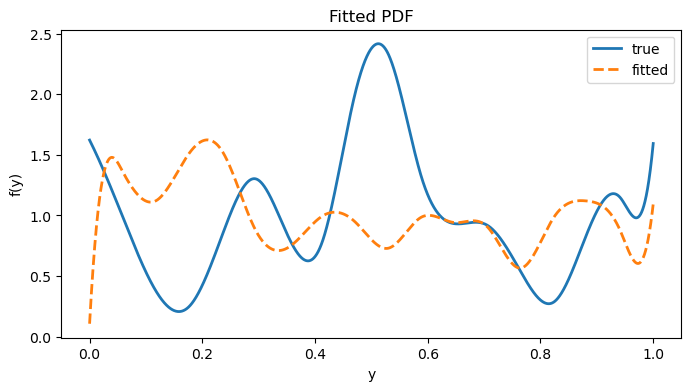

In [29]:
y_eval = np.linspace(0, 1, 10000)

fy_fit = np.zeros_like(y_eval, dtype=float)
for betak, Bk in zip(beta_hat, B):
    fy_fit += betak * Bk(y_eval)


# Plot the resulting function
plt.figure(figsize=(8,4))
plt.plot(y_eval, f(y_eval), lw=2, label="true")
plt.plot(y_eval, fy_fit, lw=2, label="fitted", ls='--')
plt.title("Fitted PDF")
plt.xlabel("y")
plt.ylabel("f(y)")
plt.legend()

In [30]:
mu_hat = gaussian_mean_basis(c_hat, beta_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)

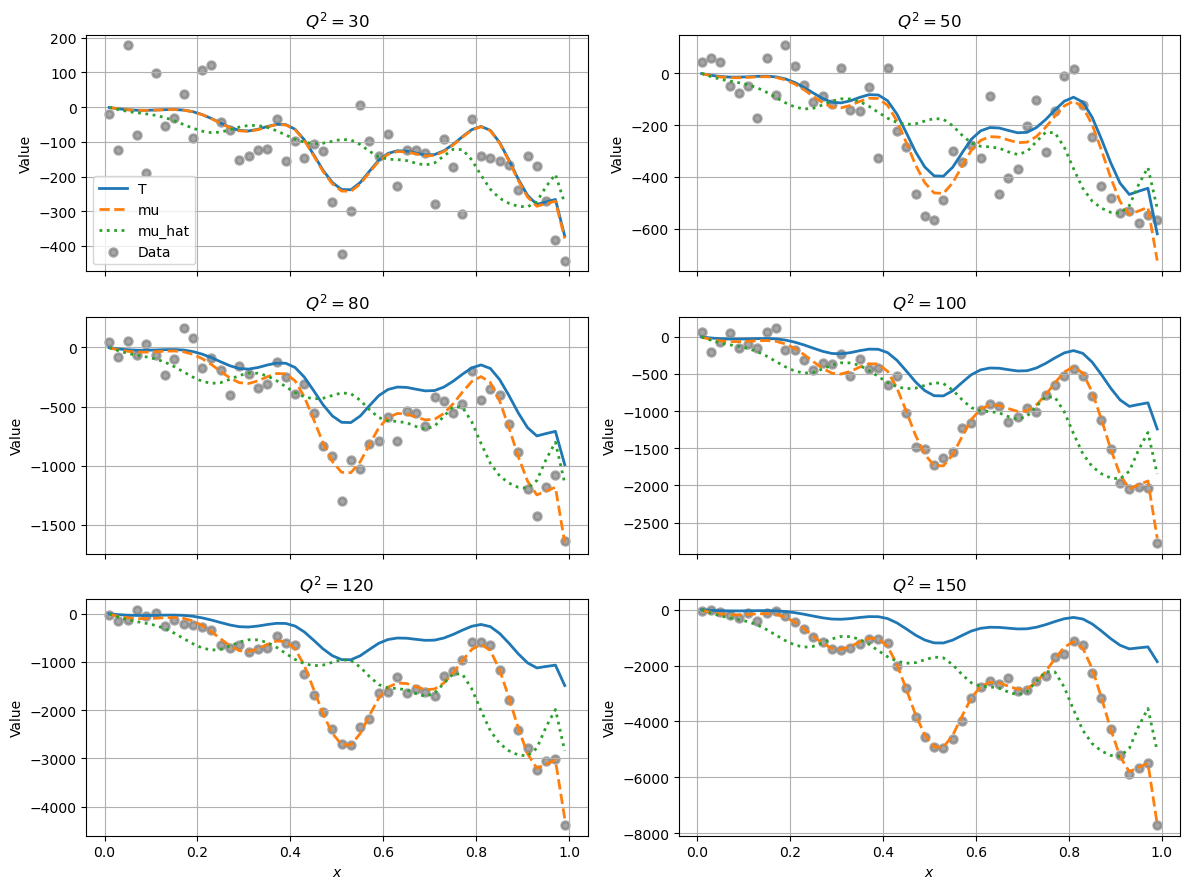

In [31]:
plot_by_Q2({"T": T, "mu": mu, "mu_hat": mu_hat, "Data": D}, xQ2=xQ2, series_styles={
    "T": dict(linestyle="-", linewidth=2, color="C0"),
    "mu": dict(linestyle="--", linewidth=2, color="C1"),
    "mu_hat": dict(linestyle=":", linewidth=2, color="C2"),
    "Data": dict(kind="scatter", color="gray", s=30, alpha=0.7)
})

## Compute One-Step Estimator

In [32]:
K = build_K_matrix(c_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)
K_prime = build_K_prime_matrix(c_hat, A, xQ2=xQ2, klin=klin, kquad=kquad)

In [33]:
c_one_step, info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, s2_diag=np.full(len(D), variance))

In [34]:
# print results
print("plug-in c estimate:", c_hat)
print("One-step c estimate:", c_one_step)
print("EIF:", info['eif'])

plug-in c estimate: 457790.72818568995
One-step c estimate: 479036.6664790436
EIF: 21245.938293353654


## Experiment

In [35]:
def setup_experiment(c, f, xQ2, gV, alpha_s, data_var, degree, M, opt="joint",
                        Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max, klin=klin, kquad=kquad, 
                        sigma_NLO=sigma_T3_NLO, nonneg_beta=True):
    """
    One-time setup for experiment: compute basis, smearing matrix, and true mean.
    These quantities don't change across simulations.

    Parameters
    ----------
    c : float
        True c.
    f : callable
        True PDF f(y).
    xQ2 : (N,2) array
        Grid points for x and Q^2.
    gV : float
        Value of gV.
    alpha_s : float
        Value of alpha_s.
    data_var : float
        Variance of the data noise.
    degree : int
        Degree of B-spline basis.
    M : int
        Number of basis functions.
    opt : str, optional
        Optimization method ("joint", "separate", or "ca").
    Lambda : float, optional
        Suppresing factor.
    Q2_min : float, optional
        Minimum Q^2.
    Q2_max : float, optional
        Maximum Q^2.
    klin : callable, optional
        First order polynomial coefficient.
    kquad : callable, optional
        Second order polynomial coefficient.
    sigma_NLO: 
        callable sigma_NLO(z, Q2) that can be vectorized in z
    nonneg_beta : bool, optional
        If True, enforce non-negativity constraint on beta.

    Returns
    -------
    dict
        Setup information including B, A, w_norm, T, mu, and other parameters.
    """
    # define local klin and kquad that uses the provided Lambda, Q2_min, Q2_max
    klin_local = lambda x: klin(x, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max)
    kquad_local = lambda x: kquad(x, Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max)

    # --- Smeared PDF T and mean mu (true values) ---
    T = T_sm(
    xQ2, f,
    sigma_NLO=lambda x, Q2: sigma_NLO(x, Q2, alpha_s=alpha_s, gV=gV),
    gV=gV,
    n_quad=2000
)

    mu = gaussian_mean(c=c, T=T, xQ2=xQ2, klin=klin_local, kquad=kquad_local)

    # --- Basis and smearing matrix ---
    B = bspline_basis(degree, M, 0, 1)
    w_norm = np.array([Bk.integrate(0, 1) for Bk in B])
    A = build_A_matrix(xQ2, B, sigma_NLO=lambda x, Q2: sigma_NLO(x, Q2, alpha_s=alpha_s, gV=gV), 
                        gV=gV, n_quad=2000)

    return {
        'B': B,
        'A': A,
        'w_norm': w_norm,
        'T': T,
        'mu': mu,
        'c': c,
        'f': f,
        'xQ2': xQ2,
        'gV': gV,
        'alpha_s': alpha_s,
        'M': M,
        'degree': degree,
        'data_var': data_var,
        'klin': klin_local,
        'kquad': kquad_local,
        'opt': opt,
        'nonneg_beta': nonneg_beta
    }


def run_single_experiment(setup_dict, diagnostics=False):
    """
    Run a single experiment with precomputed setup.
    Only generates new data and runs estimation.

    Parameters
    ----------
    setup_dict : dict
        Dictionary returned by setup_experiment().
    diagnostics : bool, optional
        If True, print diagnostic information and plots.

    Returns
    -------
    c_hat : float
        MLE estimate of c.
    c_one_step : float
        One-step corrected estimate of c.
    info : dict (only if diagnostics=True)
        Additional diagnostic information.
    """
    # Extract precomputed quantities
    A = setup_dict['A']
    B = setup_dict['B']
    w_norm = setup_dict['w_norm']
    mu = setup_dict['mu']
    T = setup_dict['T']
    c = setup_dict['c']
    f = setup_dict['f']
    xQ2 = setup_dict['xQ2']
    M = setup_dict['M']
    data_var = setup_dict['data_var']
    klin = setup_dict['klin']
    kquad = setup_dict['kquad']
    opt = setup_dict['opt']
    nonneg_beta = setup_dict['nonneg_beta']

    # =========================
    # Generate new data
    # =========================
    D = mu + np.sqrt(data_var) * np.random.randn(len(mu))
    Sigma = np.eye(len(mu)) * data_var

    # =========================
    # MLE fitting
    # =========================
    if opt == "joint":
        res, _ = fit_beta_c(D, A, v_c, v_prime_c, w_norm, xQ2, Sigma=Sigma, nonneg_beta=nonneg_beta,
                 loss_curve=True)
        beta_hat = res['beta_hat']
        c_hat = res['c_hat']
    elif opt == "separate":
        beta_hat = mle_beta(D=D, A=A, c=0, v=v_c, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, beta0=None, nonneg_beta=nonneg_beta, beta_opt="SLSQP")
        c_hat = mle_c(D=D, A=A, v=v_c, beta=beta_hat, xQ2=xQ2, Sigma=Sigma, c_opt="scipy_optimize")
        res = {'beta_hat': beta_hat, 'c_hat': c_hat}
    else:  # opt == "ca"
        beta_hat, c_hat = mle_beta_c_ca(D=D, A=A, v=v_c, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, 
                                        c0=0.0, beta0=None, beta_opt="SLSQP", c_opt="scipy_optimize", nonneg_beta=nonneg_beta, max_iter=20, eps=10)
        res = {'beta_hat': beta_hat, 'c_hat': c_hat}        
    
    mu_hat = gaussian_mean_basis(c_hat, beta_hat, A, xQ2, klin=klin, kquad=kquad)

    # =========================
    # One-step update
    # =========================
    K = build_K_matrix(c_hat, A, xQ2, klin=klin, kquad=kquad)
    K_prime = build_K_prime_matrix(c_hat, A, xQ2, klin=klin, kquad=kquad)
    c_one_step, one_step_info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, s2_diag=np.full(len(D), data_var))

    # =========================
    # Diagnostics (visual)
    # =========================
    if diagnostics:
        info = {}
  
        # ---- (1) PDF fit ----
        y_eval = np.linspace(0, 1, 5000)
        fy_fit = sum(b * Bk(y_eval) for b, Bk in zip(beta_hat, B))

  
        plt.plot(y_eval, f(y_eval), lw=2.5, label="True $f(y)$")
        plt.plot(y_eval, fy_fit, lw=2.5, ls="--", label="Fitted $\\hat f(y)$")
        plt.title("PDF fit")
        plt.xlabel("y")
        plt.ylabel("Density")
        plt.grid(True, color="0.85", linewidth=1.0)
        plt.legend()


        # ---- (2) Mean fit by Q^2 ----
        plot_by_Q2({"T": T, "mu": mu, "mu_hat": mu_hat, "Data": D}, xQ2=xQ2, series_styles={
            "T": dict(linestyle="-", linewidth=3, color="C0"),
            "mu": dict(linestyle="--", linewidth=3, color="C1"),
            "mu_hat": dict(linestyle=":", linewidth=3, color="C2"),
            "Data": dict(kind="scatter", color="gray", s=30, alpha=0.7)
        })
                

        # ---- Numerical table ----
        results_df = pd.DataFrame({
            "Parameter": ["c_hat", "c_one_step", "True c"] + [f"beta_{m}" for m in range(M)],
            "Value": np.concatenate([[c_hat, c_one_step, c], beta_hat])
        })
        print(results_df.round(6))

        # check normalization constraint
        print("Normalization constraint (w^T beta_hat):", float(w_norm @ beta_hat))
        # check fitted pdf is a valid density
        fy_integral = np.trapz(fy_fit, y_eval)
        print("Fitted pdf integrates to:", fy_integral)

        info['mle'] = res
        info['one_step'] = one_step_info
        return c_hat, c_one_step, info
    else:
        return c_hat, c_one_step


def experiment(c, f, xQ2, gV, alpha_s, data_var, degree, M, opt="joint",
               Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max, klin=klin, kquad=kquad, 
               sigma_NLO=sigma_T3_NLO, nonneg_beta=True, diagnostics=False):
    """
    Run a full experiment with data generation, MLE fitting, and one-step update.

    This is a convenience wrapper that calls setup_experiment() and run_single_experiment().
    For simulations, use setup_experiment() once, then call run_single_experiment() repeatedly.

    Parameters
    ----------
    c : float
        True c.
    f : callable
        True PDF f(y).
    xQ2 : (n_xQ2,) array
        Grid points for x and Q^2.
    gV : float
        coupling constant gV.
    alpha_s : float
        alpha_s function or value.
    data_var : float
        Variance of the data noise.
    degree : int
        Degree of B-spline basis.
    M : int
        Number of basis functions.
    opt : str, optional
        Optimization method ("joint", "separate", or "ca").
    Lambda : float, optional
        Suppresing factor.
    Q2_min : float, optional
        Minimum Q^2.
    Q2_max : float, optional
        Maximum Q^2.
    klin : callable, optional
        first order of polynomial coefficient.
    kquad : callable, optional
        second order of polynomial coefficient.
    sigma_NLO : callable, optional
        NLO part of the smearing kernel
    nonneg_beta : bool, optional
        If True, enforce non-negativity constraint on beta.
    diagnostics : bool, optional
        If True, print diagnostic information.

    Returns
    -------
    dict
        Results including fitted beta, c, one-step c, and diagnostics.
    """

    setup_dict = setup_experiment(c=c, f=f, xQ2=xQ2, gV=gV, alpha_s=alpha_s,
                                  data_var=data_var, degree=degree, M=M, opt=opt,
                                  Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max,
                                  klin=klin, kquad=kquad, sigma_NLO=sigma_NLO,
                                  nonneg_beta=nonneg_beta)
    return run_single_experiment(setup_dict, diagnostics)

In [36]:
c = 5e5

Q2_grid = [30, 50, 80, 100, 120, 150]
x_grid = np.linspace(0.01, 0.99, 30)
xQ2 = np.array([[x, Q2] for x in x_grid for Q2 in Q2_grid])

setup_dict = setup_experiment(c=c, f=f, xQ2=xQ2, gV=0.5, alpha_s=alpha_s,
                                  data_var=10000, degree=3, M=20, opt="separate",
                                  Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max,
                                  klin=klin, kquad=kquad, sigma_NLO=sigma_T3_NLO,
                                  nonneg_beta=True)

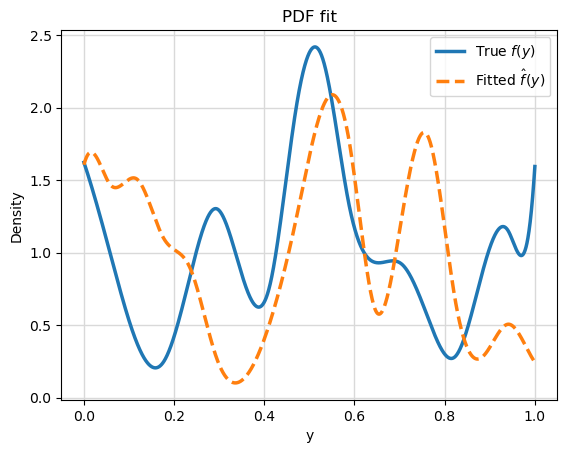

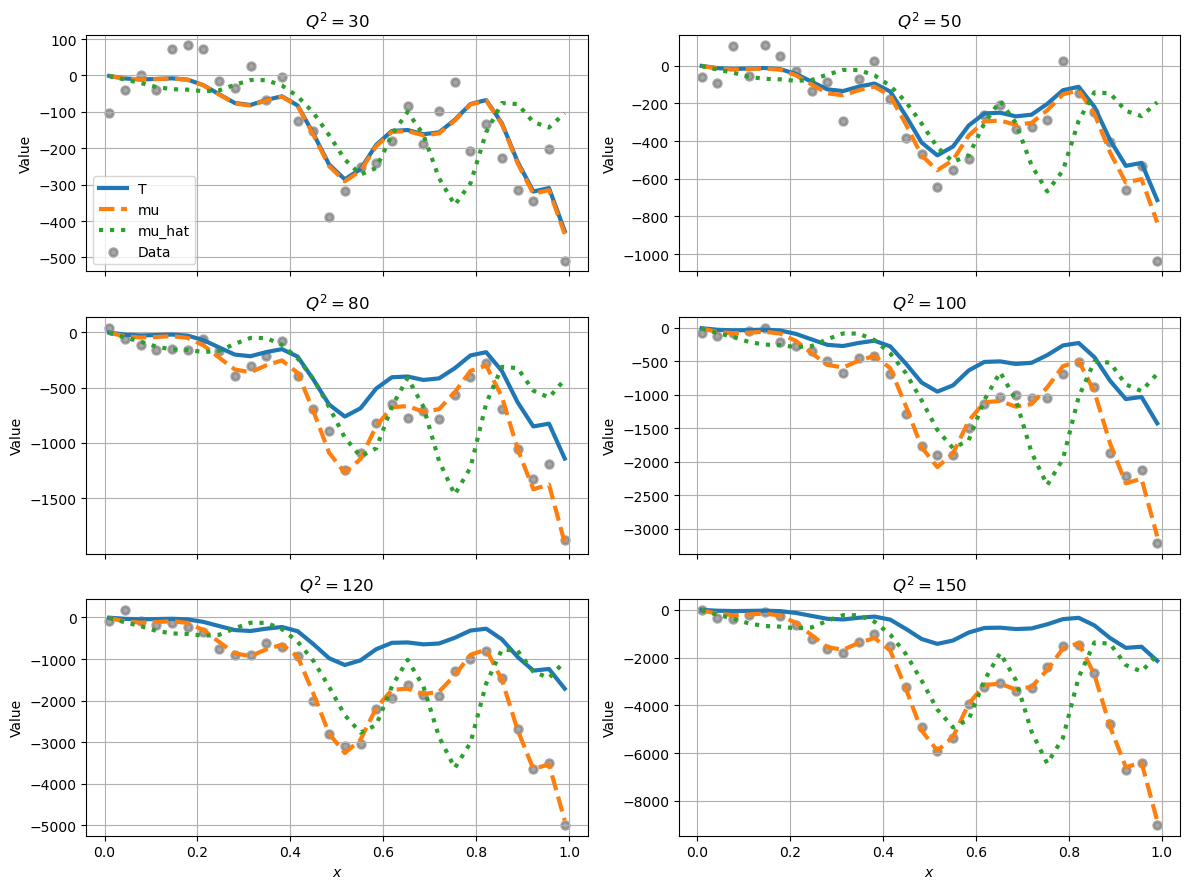

     Parameter          Value
0        c_hat  454419.631750
1   c_one_step  494897.680374
2       True c  500000.000000
3       beta_0       1.605828
4       beta_1       1.836936
5       beta_2       1.238461
6       beta_3       1.711192
7       beta_4       0.956033
8       beta_5       1.070016
9       beta_6       0.133580
10      beta_7       0.041664
11      beta_8       0.462831
12      beta_9       1.186712
13     beta_10       2.182504
14     beta_11       2.094872
15     beta_12       0.045961
16     beta_13       1.321325
17     beta_14       2.251215
18     beta_15       0.408122
19     beta_16       0.143683
20     beta_17       0.685847
21     beta_18       0.331894
22     beta_19       0.245100
Normalization constraint (w^T beta_hat): 1.000005255136223
Fitted pdf integrates to: 1.0000052010711329


In [37]:
c_hat, c_one_step, info = run_single_experiment(setup_dict, diagnostics=True)

## Simulation

In [38]:
setup_dict = setup_experiment(c=c, f=f, xQ2=xQ2, gV=0.5, alpha_s=alpha_s,
                                  data_var=10000, degree=3, M=20, opt="separate",
                                  Lambda=Lambda, Q2_min=Q2_min, Q2_max=Q2_max,
                                  klin=klin, kquad=kquad, sigma_NLO=sigma_T3_NLO,
                                  nonneg_beta=True)

In [39]:
N_sim = 100
plug_in_estimates = np.zeros(N_sim, dtype=float)
one_step_estimates = np.zeros(N_sim, dtype=float)

for sim in range(N_sim):
    print(f"Simulation {sim+1}/{N_sim}")
    c_hat, c_one_step = run_single_experiment(setup_dict, 
                                               diagnostics=False)
    plug_in_estimates[sim] = c_hat
    one_step_estimates[sim] = c_one_step

print("\nResults:")
print(f"Plug-in estimates: mean={plug_in_estimates.mean():.4f}, std={plug_in_estimates.std():.4f}")
print(f"One-step estimates: mean={one_step_estimates.mean():.4f}, std={one_step_estimates.std():.4f}")
print(f"True c: {setup_dict['c']}")

Simulation 1/100
Simulation 2/100
Simulation 3/100
Simulation 4/100
Simulation 5/100
Simulation 6/100
Simulation 7/100
Simulation 8/100
Simulation 9/100
Simulation 10/100
Simulation 11/100
Simulation 12/100
Simulation 13/100
Simulation 14/100
Simulation 15/100
Simulation 16/100
Simulation 17/100
Simulation 18/100
Simulation 19/100
Simulation 20/100
Simulation 21/100
Simulation 22/100
Simulation 23/100
Simulation 24/100
Simulation 25/100
Simulation 26/100
Simulation 27/100
Simulation 28/100
Simulation 29/100
Simulation 30/100
Simulation 31/100
Simulation 32/100
Simulation 33/100
Simulation 34/100
Simulation 35/100
Simulation 36/100
Simulation 37/100
Simulation 38/100
Simulation 39/100
Simulation 40/100
Simulation 41/100
Simulation 42/100
Simulation 43/100
Simulation 44/100
Simulation 45/100
Simulation 46/100
Simulation 47/100
Simulation 48/100
Simulation 49/100
Simulation 50/100
Simulation 51/100
Simulation 52/100
Simulation 53/100
Simulation 54/100
Simulation 55/100
Simulation 56/100
S

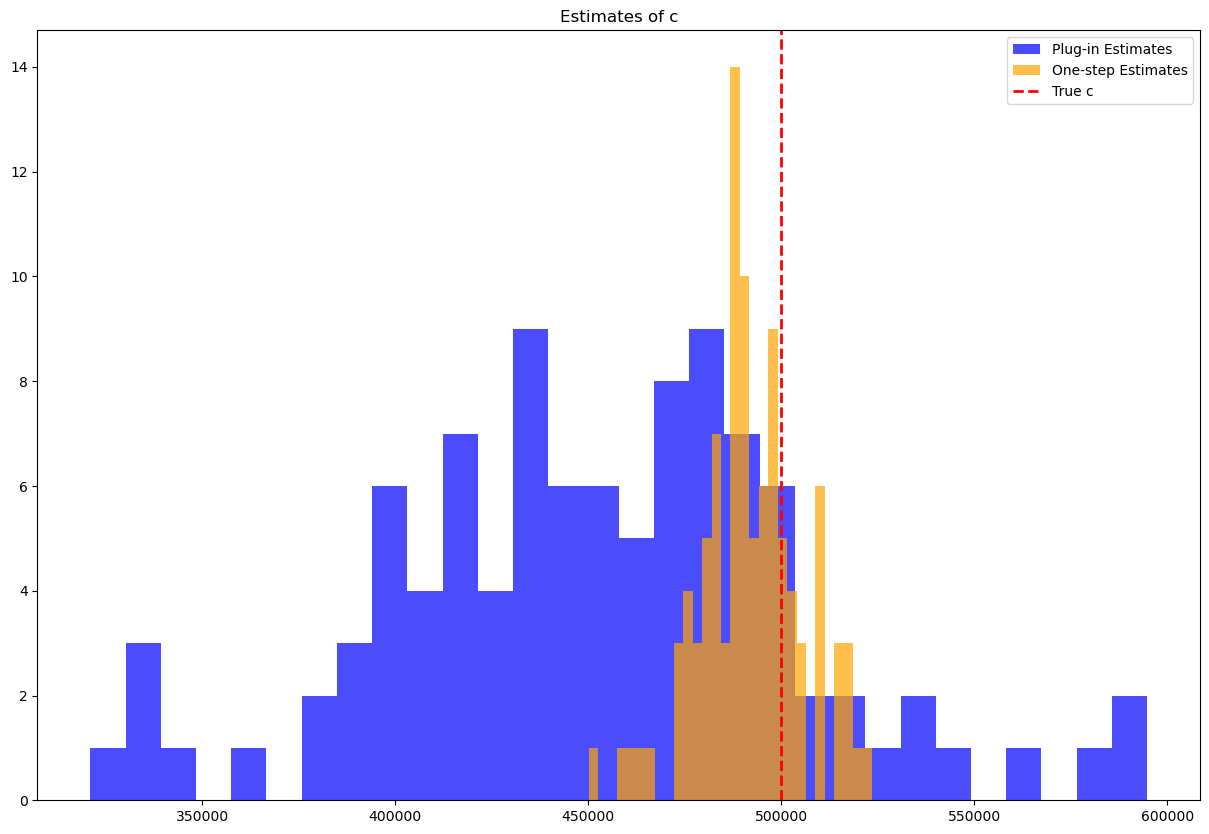

In [40]:
# plot the histograms of the estimates
plt.figure(figsize=(15,10))
plt.hist(plug_in_estimates, bins=30, alpha=0.7, color='blue', label='Plug-in Estimates')
plt.hist(one_step_estimates, bins=30, alpha=0.7, color='orange', label='One-step Estimates')
plt.axvline(setup_dict['c'], color='red', linestyle='dashed', linewidth=2, label='True c')
plt.title("Estimates of c")
plt.legend()